# Simultaneous Perturbation Stochastic Approximation (SPSA)
## Mathematical Optimization & Forward-Only Neural Network Training Without Backpropagation

**Implementation by**: Ananth Shyam, Rama Narasimha, and Mahan Bhimireddy  
**Reference Paper**: *B. Wulff, J. Schuecker, C. Bauckhage. SPSA for Layer-Wise Training of Deep Networks. ICANN 2018, LNCS 11141, pp. 564–573.*

This notebook demonstrates **Simultaneous Perturbation Stochastic Approximation (SPSA)** across two parts:
1. **Part 1 — Mathematical Function Optimization**: Optimizing a coupled non-convex cubic polynomial using Holistic SPSA, compared against a Coordinate-Wise Finite-Difference (FDSA) baseline, exact Gradient Descent (GD), and noisy Stochastic Gradient Descent (SGD).
2. **Part 2 — Neural Network Classification Without Backpropagation**: Training a 4-layer neural network ($2 \to 5 \to 5 \to 5 \to 1$, 81 parameters) on concentric circles with **zero backpropagation**, comparing Holistic SPSA and Layer-Wise SPSA (Wulff et al., 2018) against backpropagation-based GD and mini-batch SGD on a held-out test set.

## 1. Theoretical Background

### 1.1 Classical (Holistic) SPSA (Spall, 1992/1998)
Standard central Finite Differences (FDSA) estimates a $D$-dimensional gradient by perturbing one parameter at a time, requiring **$2D$ function evaluations** per step:
$$\hat{g}_i(\theta) = \frac{f(\theta + c \mathbf{e}_i) - f(\theta - c \mathbf{e}_i)}{2c}$$

**SPSA** perturbs **all $D$ parameters simultaneously** using a random Rademacher vector $\Delta_k \in \{-1, +1\}^D$ (each entry $\pm 1$ with equal probability):
$$\hat{g}_{k, i}(\theta_k) = \frac{f(\theta_k + c_k \Delta_k) - f(\theta_k - c_k \Delta_k)}{2 c_k \Delta_{k, i}}$$

- **Why Rademacher $\{-1, +1\}$?** As noted in Wulff et al. (Section 2, p. 566), $\Delta_{k,i}$ must be zero-mean with finite inverse moments $\mathbb{E}[\Delta_{k,i}^{-1}]$ and $\text{Var}(\Delta_{k,i}^{-1})$. Gaussian perturbations violate this (dividing by values near 0 explodes), whereas $\{-1, +1\}$ satisfies it cleanly.
- **Cost**: Only **2 forward evaluations** per step regardless of $D$.

### 1.2 Layer-Wise SPSA (Wulff et al., ICANN 2018 — Algorithm 2)
When $D$ is large (e.g., deep neural networks), perturbing every weight simultaneously introduces high gradient-estimation variance that scales with $D$.

**Layer-Wise SPSA** reduces this variance by updating **one layer at a time**:
- In each epoch, iterate through layers $l = 1, \dots, L$ (bottom-up).
- Freeze all other layers $j \neq l$ and run $t_{\max}$ SPSA steps on $(W_l, b_l)$ using decaying schedules:
  $$a_t = \frac{a}{t}, \qquad c_t = \frac{c}{t^{1/6}}$$
- Reset $a_t$ and $c_t$ when moving to the next layer (similar to cyclic learning rates / warm restarts; Wulff et al., Section 5).
- Training uses **forward passes only**—no backward pass or computation graph is needed.

In [1]:
# Environment Setup and Imports
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
import torch

# Fix random seeds for reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Environment initialized successfully.")
print(f"PyTorch version: {torch.__version__} | NumPy: {np.__version__}")

Environment initialized successfully.
PyTorch version: 2.11.0+cu130 | NumPy: 2.1.3


## 2. Part 1: Optimizing a Coupled Non-Convex Mathematical Function

### Objective Function
$$f(x, y) = x^3 + y^3 - 3xy + 1.0$$

- **Analytic Gradient**: $\nabla f(x, y) = \begin{bmatrix} 3x^2 - 3y \\ 3y^2 - 3x \end{bmatrix}$
- **Saddle Point**: $(0.0, 0.0)$ with $f(0, 0) = 1.0$ (Hessian eigenvalues $\lambda = \pm 3$).
- **Strict Local Minimum**: $(1.0, 1.0)$ with $f(1, 1) = 0.0$ (Hessian eigenvalues $\lambda = 3, 9$).  
  *(Note: Because $f$ is a cubic polynomial, it is unbounded below as $x, y \to -\infty$, so $(1, 1)$ is a **local** minimum rather than a global minimum.)*
- **Starting Point**: $\theta_0 = (2.0, 0.3)$ with $f(\theta_0) = 7.2270$ (inside the basin of attraction of $(1, 1)$).

### Compared Methods in Part 1
1. **Holistic SPSA**: Perturbs $(x, y)$ simultaneously using Rademacher $\Delta_k \in \{-1, +1\}^2$ (**2 evals/step**).
2. **Coordinate-Wise FDSA (Baseline)**: Perturbs one scalar coordinate at a time (**4 evals/step**). Note that for a single scalar coordinate, $\delta_i \in \{-1, +1\}$ cancels out in $\frac{f(\theta + c_k \delta_i e_i) - f(\theta - c_k \delta_i e_i)}{2 c_k \delta_i}$, so in 2D this is deterministic central finite-difference coordinate descent. It serves as a clean baseline illustrating how decoupling coordinates removes cross-term perturbation noise at 2× the evaluation cost.
3. **GD (Exact Analytical Gradient)**: Uses $\nabla f(x, y)$ directly.
4. **SGD (Noisy Gradient)**: Adds zero-mean Gaussian noise ($\sigma = 0.05$) to $\nabla f(x, y)$.

In [2]:
# Part 1: Objective Function, Exact Gradient, and 4 Optimizers

def cubic_loss(theta):
    x, y = theta[0], theta[1]
    return float(x**3 + y**3 - 3.0 * x * y + 1.0)


def cubic_grad(theta):
    x, y = theta[0], theta[1]
    return np.array([3.0 * x**2 - 3.0 * y, 3.0 * y**2 - 3.0 * x], dtype=np.float64)


def clip_vector(vec, max_norm):
    norm = np.linalg.norm(vec)
    if norm > max_norm:
        return vec * (max_norm / norm)
    return vec


# 1. Holistic SPSA (2 function evaluations per step)
def run_holistic_spsa(loss_fn, theta_init, iterations=150,
                      a=0.05, c=0.06, A=12.0, alpha=0.602, gamma=0.101,
                      max_grad_norm=20.0, seed=42):
    rng = np.random.default_rng(seed)
    theta = np.array(theta_init, dtype=np.float64)
    loss_hist = [loss_fn(theta)]
    traj = [theta.copy()]
    evals = [0]

    for k in range(iterations):
        ak = a / ((k + 1 + A) ** alpha)
        ck = c / ((k + 1) ** gamma)

        # Simultaneous Rademacher perturbation in {-1, +1}^2
        delta = rng.choice([-1.0, 1.0], size=theta.shape)
        y_plus = loss_fn(theta + ck * delta)
        y_minus = loss_fn(theta - ck * delta)

        g_hat = (y_plus - y_minus) / (2.0 * ck * delta)
        g_hat = clip_vector(g_hat, max_grad_norm)

        theta = theta - ak * g_hat
        loss_hist.append(loss_fn(theta))
        traj.append(theta.copy())
        evals.append(evals[-1] + 2)

    return theta, loss_hist, np.array(traj), evals


# 2. Coordinate-Wise FDSA Baseline (2*p = 4 function evaluations per step)
def run_coordinate_fdsa(loss_fn, theta_init, iterations=150,
                        a=0.05, c=0.06, A=12.0, alpha=0.602, gamma=0.101,
                        max_grad_norm=20.0):
    theta = np.array(theta_init, dtype=np.float64)
    loss_hist = [loss_fn(theta)]
    traj = [theta.copy()]
    evals = [0]
    dim = len(theta)

    for k in range(iterations):
        ak = a / ((k + 1 + A) ** alpha)
        ck = c / ((k + 1) ** gamma)

        # Update one coordinate at a time using central finite differences
        for i in range(dim):
            t_plus = theta.copy()
            t_minus = theta.copy()
            t_plus[i] += ck
            t_minus[i] -= ck

            g_i = (loss_fn(t_plus) - loss_fn(t_minus)) / (2.0 * ck)
            g_i = np.clip(g_i, -max_grad_norm, max_grad_norm)
            theta[i] = theta[i] - ak * g_i

        loss_hist.append(loss_fn(theta))
        traj.append(theta.copy())
        evals.append(evals[-1] + 2 * dim)

    return theta, loss_hist, np.array(traj), evals


# 3. Exact Gradient Descent (GD)
def run_gd(loss_fn, grad_fn, theta_init, lr=0.03, iterations=150, max_grad_norm=20.0):
    theta = np.array(theta_init, dtype=np.float64)
    loss_hist = [loss_fn(theta)]
    traj = [theta.copy()]

    for _ in range(iterations):
        grad = clip_vector(grad_fn(theta), max_grad_norm)
        theta = theta - lr * grad
        loss_hist.append(loss_fn(theta))
        traj.append(theta.copy())

    return theta, loss_hist, np.array(traj)


# 4. Stochastic Gradient Descent (Noisy Gradient)
def run_sgd(loss_fn, grad_fn, theta_init, lr=0.03, noise_std=0.05,
            iterations=150, max_grad_norm=20.0, seed=42):
    rng = np.random.default_rng(seed)
    theta = np.array(theta_init, dtype=np.float64)
    loss_hist = [loss_fn(theta)]
    traj = [theta.copy()]

    for k in range(iterations):
        step_lr = lr / ((k + 1) ** 0.05)
        noisy_grad = grad_fn(theta) + rng.normal(0.0, noise_std, size=theta.shape)
        noisy_grad = clip_vector(noisy_grad, max_grad_norm)
        theta = theta - step_lr * noisy_grad
        loss_hist.append(loss_fn(theta))
        traj.append(theta.copy())

    return theta, loss_hist, np.array(traj)

In [3]:
# Execute Part 1 Optimization and Print Consistent Summary Tables
theta_init = np.array([2.0, 0.3], dtype=np.float64)
local_min = np.array([1.0, 1.0], dtype=np.float64)
saddle_pt = np.array([0.0, 0.0], dtype=np.float64)
iters = 150

th_spsa, loss_spsa, traj_spsa, evals_spsa = run_holistic_spsa(
    cubic_loss, theta_init, iterations=iters, seed=SEED
)
th_fdsa, loss_fdsa, traj_fdsa, evals_fdsa = run_coordinate_fdsa(
    cubic_loss, theta_init, iterations=iters
)
th_gd, loss_gd, traj_gd = run_gd(
    cubic_loss, cubic_grad, theta_init, lr=0.03, iterations=iters
)
th_sgd, loss_sgd, traj_sgd = run_sgd(
    cubic_loss, cubic_grad, theta_init, lr=0.03, noise_std=0.05, iterations=iters, seed=SEED
)

# Table 1A: Final Summary
print("=" * 92)
print(" PART 1: FINAL OPTIMIZATION SUMMARY ON f(x, y) = x^3 + y^3 - 3xy + 1")
print("=" * 92)
print(f"{'Method':<28} | {'Evals/Step':<12} | {'Final Loss':<12} | {'Final (x, y)'}")
print("-" * 92)
summary_rows = [
    ("1. Holistic SPSA",           "2 forward",  loss_spsa[-1], th_spsa),
    ("2. Coordinate-Wise FDSA",    "4 forward",  loss_fdsa[-1], th_fdsa),
    ("3. GD (Exact Analytical)",   "Exact Grad", loss_gd[-1],   th_gd),
    ("4. SGD (Noisy Gradient)",    "Noisy Grad", loss_sgd[-1],  th_sgd),
]
for name, cost, fl, th in summary_rows:
    print(f"{name:<28} | {cost:<12} | {fl:<12.6f} | ({th[0]:.4f}, {th[1]:.4f})")
print("=" * 92)

# Table 1B: Iteration-Wise Checkpoints (every 15 iterations)
print("\n" + "=" * 92)
print(" PART 1: CONVERGENCE CHECKPOINTS (EVERY 15 ITERATIONS)")
print("=" * 92)
print(f"{'Iter':<6} | {'1. Holistic SPSA':<18} | {'2. Coord. FDSA':<18} | {'3. GD (Exact)':<16} | {'4. SGD (Noisy)'}")
print("-" * 92)
for step in range(0, iters + 1, 15):
    print(
        f"{step:<6} | {loss_spsa[step]:<18.6f} | {loss_fdsa[step]:<18.6f} | "
        f"{loss_gd[step]:<16.6f} | {loss_sgd[step]:.6f}"
    )
print("=" * 92)

 PART 1: FINAL OPTIMIZATION SUMMARY ON f(x, y) = x^3 + y^3 - 3xy + 1
Method                       | Evals/Step   | Final Loss   | Final (x, y)
--------------------------------------------------------------------------------------------
1. Holistic SPSA             | 2 forward    | 0.001556     | (1.0232, 1.0219)
2. Coordinate-Wise FDSA      | 4 forward    | 0.000112     | (1.0004, 0.9941)
3. GD (Exact Analytical)     | Exact Grad   | 0.000000     | (1.0000, 1.0000)
4. SGD (Noisy Gradient)      | Noisy Grad   | 0.000005     | (1.0011, 1.0015)

 PART 1: CONVERGENCE CHECKPOINTS (EVERY 15 ITERATIONS)
Iter   | 1. Holistic SPSA   | 2. Coord. FDSA     | 3. GD (Exact)    | 4. SGD (Noisy)
--------------------------------------------------------------------------------------------
0      | 7.227000           | 7.227000           | 7.227000         | 7.227000
15     | 0.226168           | 0.578728           | 0.000506         | 0.001066
30     | 0.036917           | 0.112899           | 0.000003 

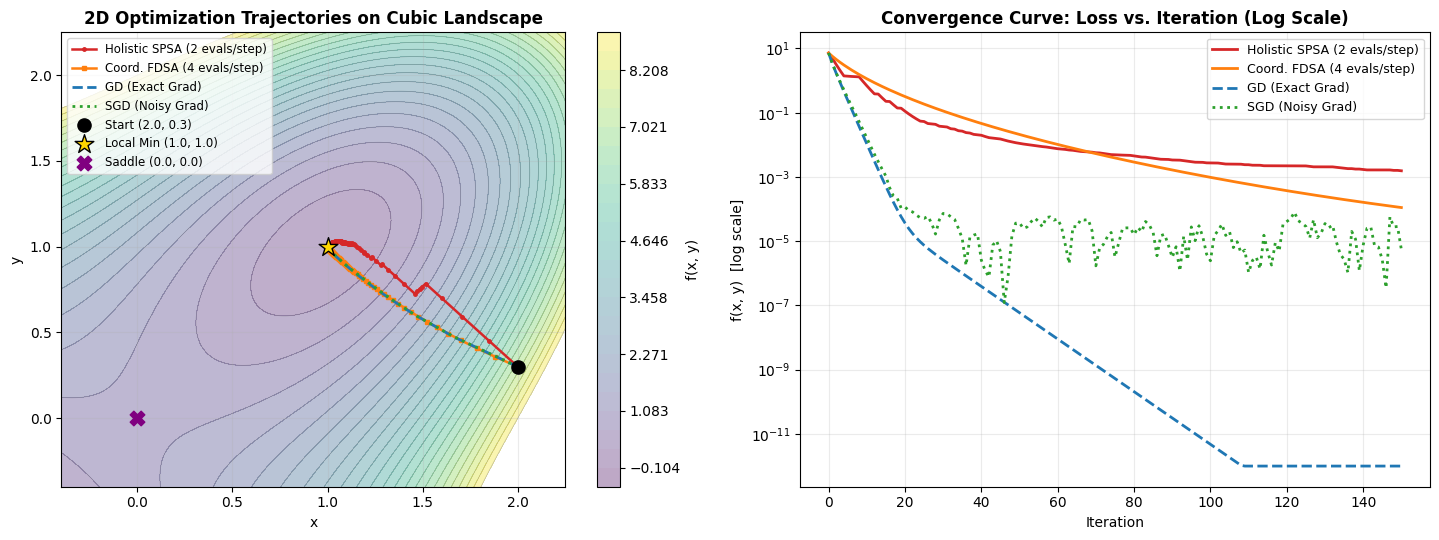

In [4]:
# Part 1 Visualizations: 2D Optimization Trajectories & Log-Loss Convergence
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.5))

# --- Left Subplot: 2D Contour & Trajectories ---
ax = axes[0]
gx = np.linspace(-0.5, 2.3, 250)
gy = np.linspace(-0.5, 2.3, 250)
X, Y = np.meshgrid(gx, gy)
Z = X**3 + Y**3 - 3.0 * X * Y + 1.0

levels = np.linspace(-0.5, 9.0, 25)
contour = ax.contourf(X, Y, Z, levels=levels, cmap="viridis", alpha=0.35)
ax.contour(X, Y, Z, levels=levels, colors="gray", linewidths=0.5, alpha=0.5)
fig.colorbar(contour, ax=ax, label="f(x, y)")

ax.plot(traj_spsa[:, 0], traj_spsa[:, 1], "-o", markersize=2.5, linewidth=1.8, color="#d62728", label="Holistic SPSA (2 evals/step)")
ax.plot(traj_fdsa[:, 0], traj_fdsa[:, 1], "-s", markersize=2.5, linewidth=1.8, color="#ff7f0e", label="Coord. FDSA (4 evals/step)")
ax.plot(traj_gd[:, 0],   traj_gd[:, 1],   "--", linewidth=2.0, color="#1f77b4", label="GD (Exact Grad)")
ax.plot(traj_sgd[:, 0],  traj_sgd[:, 1],  ":",  linewidth=2.0, color="#2ca02c", label="SGD (Noisy Grad)")

ax.scatter(*theta_init, color="black", s=90, zorder=6, label="Start (2.0, 0.3)")
ax.scatter(*local_min,  color="gold", edgecolor="black", marker="*", s=200, zorder=7, label="Local Min (1.0, 1.0)")
ax.scatter(*saddle_pt,  color="purple", marker="X", s=110, zorder=6, label="Saddle (0.0, 0.0)")

ax.set_title("2D Optimization Trajectories on Cubic Landscape", fontsize=12, fontweight="bold")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_xlim(-0.4, 2.25)
ax.set_ylim(-0.4, 2.25)
ax.legend(fontsize=8.5, loc="upper left")
ax.grid(alpha=0.25)

# --- Right Subplot: Log-Loss Curve ---
ax = axes[1]
eps = 1e-12
iters_axis = np.arange(iters + 1)
ax.semilogy(iters_axis, np.maximum(loss_spsa, eps), linewidth=2.0, color="#d62728", label="Holistic SPSA (2 evals/step)")
ax.semilogy(iters_axis, np.maximum(loss_fdsa, eps), linewidth=2.0, color="#ff7f0e", label="Coord. FDSA (4 evals/step)")
ax.semilogy(iters_axis, np.maximum(loss_gd,   eps), "--", linewidth=2.0, color="#1f77b4", label="GD (Exact Grad)")
ax.semilogy(iters_axis, np.maximum(loss_sgd,  eps), ":",  linewidth=2.0, color="#2ca02c", label="SGD (Noisy Grad)")

ax.set_title("Convergence Curve: Loss vs. Iteration (Log Scale)", fontsize=12, fontweight="bold")
ax.set_xlabel("Iteration")
ax.set_ylabel("f(x, y)  [log scale]")
ax.legend(fontsize=9)
ax.grid(True, which="both", alpha=0.25)

plt.tight_layout()
plt.show()

## 3. Part 2: Neural Network Classification Without Backpropagation

### 3.1 Task & Architecture Specification
- **Dataset**: Non-linear Concentric Circles ($N = 250$, factor $= 0.4$, noise $\sigma = 0.06$), split **80% train (200) / 20% test (50)** with stratification so we measure real generalization.
- **Network Topology**: $2 \to 5 \to 5 \to 5 \to 1$ ($L = 4$ layers, **81 total parameters**), matching the 2-class topology in Wulff et al. (Section 4.1, p. 570).
- **Activation Function**: Hidden layers use $\tanh(\beta z)$ with $\beta = 0.5$. The output layer is kept **linear** to avoid output saturation (note: Wulff et al. apply $\tanh(\beta z)$ on the output layer as well).
- **Objective Function**: Scaled sum of squared residuals (equivalent to Equation 9 in Wulff et al. up to the $\frac{1}{2}$ factor; since $y_i \in \{-1, +1\}$, $(f(x_i) - y_i)^2 = (1 - y_i f(x_i))^2$):
  $$L(\boldsymbol{\theta}) = \frac{1}{2} \sum_{i=1}^{N_{\text{train}}} \bigl(f(\mathbf{x}_i; \boldsymbol{\theta}) - y_i\bigr)^2$$
- **Fairness Guarantee**: All 4 optimizers start from the **exact same initial parameters `p0`** (`seed=42`).

### 3.2 Four Compared Optimizers
1. **Holistic SPSA (0 Backprop)**: Perturbs all 81 parameters simultaneously. Runs $L \times t_{\max} = 120$ updates (240 forward passes) per epoch so its compute budget per epoch matches Layer-Wise SPSA.
2. **Layer-Wise SPSA (0 Backprop — Wulff et al., Algorithm 2)**: Cycles bottom-up through layers $l = 1, \dots, 4$, updating only $(W_l, b_l)$ for $t_{\max} = 30$ steps with $a_t = a/t$, $c_t = c/t^{1/6}$.
3. **GD (Full-Batch Backprop)**: Standard full-batch gradient descent using PyTorch autograd (1 update / 3 full-dataset eval equivalents per epoch).
4. **SGD (Mini-Batch Backprop)**: Mini-batch gradient descent (batch size 25, shuffled every epoch). Each mini-batch processes $\frac{25}{200}$ of the training set, so one full epoch equals **3 full-dataset eval equivalents** (same dataset-pass cost as GD).

In [5]:
# Part 2: Neural Network Forward Pass, Loss, Accuracy, and Parameter Initialization

def init_network_params(dims=(2, 5, 5, 5, 1), seed=42):
    """Initialize weights and biases with standard normal distribution."""
    torch.manual_seed(seed)
    params = []
    for i in range(len(dims) - 1):
        w = torch.randn(dims[i], dims[i + 1], dtype=torch.float32)
        b = torch.randn(1, dims[i + 1], dtype=torch.float32)
        params.append(w)
        params.append(b)
    return params


def forward_pass(x, params, beta=0.5):
    """Pure forward pass: 3 tanh hidden layers + 1 linear output layer."""
    a = x
    num_layers = len(params) // 2
    for l in range(num_layers - 1):
        w = params[2 * l]
        b = params[2 * l + 1]
        a = torch.tanh(beta * (a @ w + b))
    w_out = params[-2]
    b_out = params[-1]
    return a @ w_out + b_out


def compute_loss(preds, targets):
    """Scaled sum-of-squared-residuals loss: 0.5 * sum((f(x) - y)^2)."""
    return 0.5 * torch.sum((preds - targets) ** 2)


def compute_accuracy(preds, targets):
    """Binary classification accuracy (%) using sign(preds) vs {-1, +1} labels."""
    pred_labels = torch.where(preds >= 0, 1.0, -1.0)
    correct = (pred_labels == targets).float().sum().item()
    return 100.0 * correct / len(targets)


def record_metrics(history, x_train, y_train, x_test, y_test, params, evals, beta=0.5):
    """Evaluate and log train/test loss and accuracy without tracking gradients."""
    with torch.no_grad():
        tr_preds = forward_pass(x_train, params, beta)
        te_preds = forward_pass(x_test, params, beta)
        history["train_loss"].append(compute_loss(tr_preds, y_train).item())
        history["test_loss"].append(compute_loss(te_preds, y_test).item())
        history["train_acc"].append(compute_accuracy(tr_preds, y_train))
        history["test_acc"].append(compute_accuracy(te_preds, y_test))
        history["evals"].append(evals)

In [6]:
# Part 2: Implementation of the 4 Optimizers (2 Derivative-Free SPSA, 2 Backprop)

# 1. Layer-Wise SPSA (Wulff et al., ICANN 2018 Algorithm 2 — Strictly 0 Backprop)
def train_layerwise_spsa(x_train, y_train, x_test, y_test, init_params,
                         epochs=100, t_max=30, a=0.02, c=0.10, beta=0.5, seed=42):
    torch.manual_seed(seed)
    params = [p.clone().detach() for p in init_params]
    num_layers = len(params) // 2

    history = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": [], "evals": []}
    total_evals = 0.0
    record_metrics(history, x_train, y_train, x_test, y_test, params, total_evals, beta)

    t0 = time.perf_counter()
    with torch.no_grad():
        for epoch in range(1, epochs + 1):
            # Bottom-up sweep across layers
            for l in range(num_layers):
                idx_w = 2 * l
                idx_b = 2 * l + 1
                w = params[idx_w]
                b = params[idx_b]

                for t in range(1, t_max + 1):
                    at = a / float(t)
                    ct = c / (float(t) ** (1.0 / 6.0))

                    # Rademacher perturbations in {-1, +1} for layer l only
                    dw = (torch.randint(0, 2, w.shape) * 2 - 1).float()
                    db = (torch.randint(0, 2, b.shape) * 2 - 1).float()

                    # Positive perturbation
                    params[idx_w] = w + ct * dw
                    params[idx_b] = b + ct * db
                    loss_plus = compute_loss(forward_pass(x_train, params, beta), y_train)

                    # Negative perturbation
                    params[idx_w] = w - ct * dw
                    params[idx_b] = b - ct * db
                    loss_minus = compute_loss(forward_pass(x_train, params, beta), y_train)
                    total_evals += 2.0

                    # SPSA gradient estimate & update for layer l
                    ghat_w = (loss_plus - loss_minus) / (2.0 * ct * dw)
                    ghat_b = (loss_plus - loss_minus) / (2.0 * ct * db)
                    w = w - at * ghat_w
                    b = b - at * ghat_b

                params[idx_w] = w
                params[idx_b] = b

            record_metrics(history, x_train, y_train, x_test, y_test, params, total_evals, beta)

    history["runtime"] = time.perf_counter() - t0
    return params, history


# 2. Holistic SPSA (Spall 1992 — Perturbs all 81 parameters simultaneously; 0 Backprop)
def train_holistic_spsa(x_train, y_train, x_test, y_test, init_params,
                        epochs=100, t_max=30, a=0.02, c=0.10, beta=0.5, seed=42):
    torch.manual_seed(seed)
    params = [p.clone().detach() for p in init_params]
    num_layers = len(params) // 2

    history = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": [], "evals": []}
    total_evals = 0.0
    record_metrics(history, x_train, y_train, x_test, y_test, params, total_evals, beta)

    t0 = time.perf_counter()
    with torch.no_grad():
        for epoch in range(1, epochs + 1):
            # Same number of steps per epoch (num_layers * t_max) as Layer-Wise SPSA
            for _ in range(num_layers):
                for t in range(1, t_max + 1):
                    at = a / float(t)
                    ct = c / (float(t) ** (1.0 / 6.0))

                    deltas = [(torch.randint(0, 2, p.shape) * 2 - 1).float() for p in params]

                    # Positive perturbation across all parameters
                    params_plus = [p + ct * d for p, d in zip(params, deltas)]
                    loss_plus = compute_loss(forward_pass(x_train, params_plus, beta), y_train)

                    # Negative perturbation across all parameters
                    params_minus = [p - ct * d for p, d in zip(params, deltas)]
                    loss_minus = compute_loss(forward_pass(x_train, params_minus, beta), y_train)
                    total_evals += 2.0

                    # Simultaneous update across all parameters
                    for i in range(len(params)):
                        ghat = (loss_plus - loss_minus) / (2.0 * ct * deltas[i])
                        params[i] = params[i] - at * ghat

            record_metrics(history, x_train, y_train, x_test, y_test, params, total_evals, beta)

    history["runtime"] = time.perf_counter() - t0
    return params, history


# 3. Full-Batch Gradient Descent (Backpropagation via PyTorch Autograd)
def train_full_batch_gd(x_train, y_train, x_test, y_test, init_params,
                        epochs=100, lr=0.005, beta=0.5):
    params = [p.clone().detach().requires_grad_(True) for p in init_params]
    optimizer = torch.optim.SGD(params, lr=lr)

    history = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": [], "evals": []}
    total_evals = 0.0
    record_metrics(history, x_train, y_train, x_test, y_test, params, total_evals, beta)

    t0 = time.perf_counter()
    for epoch in range(1, epochs + 1):
        optimizer.zero_grad()
        loss = compute_loss(forward_pass(x_train, params, beta), y_train)
        loss.backward()
        optimizer.step()

        # 1 full forward pass + ~2 forward-equivalents for backward pass
        total_evals += 3.0
        record_metrics(history, x_train, y_train, x_test, y_test, params, total_evals, beta)

    history["runtime"] = time.perf_counter() - t0
    return [p.detach() for p in params], history


# 4. Mini-Batch SGD (Backpropagation via PyTorch Autograd)
def train_minibatch_sgd(x_train, y_train, x_test, y_test, init_params,
                        epochs=100, lr=0.01, batch_size=25, beta=0.5, seed=42):
    torch.manual_seed(seed)
    params = [p.clone().detach().requires_grad_(True) for p in init_params]
    optimizer = torch.optim.SGD(params, lr=lr)

    history = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": [], "evals": []}
    total_evals = 0.0
    record_metrics(history, x_train, y_train, x_test, y_test, params, total_evals, beta)

    n_samples = len(x_train)
    t0 = time.perf_counter()
    for epoch in range(1, epochs + 1):
        perm = torch.randperm(n_samples)
        for start in range(0, n_samples, batch_size):
            idx = perm[start : start + batch_size]
            xb = x_train[idx]
            yb = y_train[idx]

            optimizer.zero_grad()
            loss_b = compute_loss(forward_pass(xb, params, beta), yb)
            loss_b.backward()
            optimizer.step()

            # Scale evaluation cost by the fraction of the dataset in this mini-batch
            total_evals += 3.0 * (len(xb) / float(n_samples))

        record_metrics(history, x_train, y_train, x_test, y_test, params, total_evals, beta)

    history["runtime"] = time.perf_counter() - t0
    return [p.detach() for p in params], history

In [7]:
# Generate Dataset (80/20 Train/Test Split) and Run All 4 Neural Network Optimizers
x_raw, y_cls = make_circles(n_samples=250, noise=0.06, factor=0.4, random_state=SEED)
y_signed = np.where(y_cls == 1, 1.0, -1.0)

x_tr_np, x_te_np, y_tr_np, y_te_np = train_test_split(
    x_raw, y_signed, test_size=0.20, random_state=SEED, stratify=y_cls
)

x_train = torch.tensor(x_tr_np, dtype=torch.float32)
y_train = torch.tensor(y_tr_np[:, None], dtype=torch.float32)
x_test  = torch.tensor(x_te_np, dtype=torch.float32)
y_test  = torch.tensor(y_te_np[:, None], dtype=torch.float32)

# Shared initial parameters for all 4 optimizers
p0 = init_network_params((2, 5, 5, 5, 1), seed=SEED)
n_params = sum(p.numel() for p in p0)
print(f"Dataset: {len(x_train)} train / {len(x_test)} test samples | Network parameters: {n_params}")

with torch.no_grad():
    init_tr_loss = compute_loss(forward_pass(x_train, p0), y_train).item()
    init_te_acc  = compute_accuracy(forward_pass(x_test, p0), y_test)
print(f"Initial State -> Train Loss: {init_tr_loss:.2f} | Test Accuracy: {init_te_acc:.1f}%\n")

# Run all 4 methods
p_hol, hist_hol = train_holistic_spsa(x_train, y_train, x_test, y_test, p0, epochs=100, t_max=30, a=0.02, c=0.10, seed=SEED)
p_lw,  hist_lw  = train_layerwise_spsa(x_train, y_train, x_test, y_test, p0, epochs=100, t_max=30, a=0.02, c=0.10, seed=SEED)
p_gd,  hist_gd  = train_full_batch_gd(x_train, y_train, x_test, y_test, p0, epochs=100, lr=0.005)
p_sgd, hist_sgd = train_minibatch_sgd(x_train, y_train, x_test, y_test, p0, epochs=100, lr=0.01, batch_size=25, seed=SEED)

# Summary Table
print("=" * 102)
print(" PART 2: FINAL NEURAL NETWORK COMPARISON (100 EPOCHS)")
print("=" * 102)
print(f"{'Optimizer':<24} | {'Backprop':<9} | {'Train Loss':<10} | {'Train Acc':<9} | {'Test Acc':<8} | {'Full Evals':<10} | {'Time (s)'}")
print("-" * 102)
results = [
    ("1. Holistic SPSA",   "No",  hist_hol),
    ("2. Layer-Wise SPSA", "No",  hist_lw),
    ("3. GD (Full-Batch)", "Yes", hist_gd),
    ("4. SGD (Mini-Batch)","Yes", hist_sgd),
]
for name, bp, h in results:
    print(
        f"{name:<24} | {bp:<9} | {h['train_loss'][-1]:<10.4f} | "
        f"{h['train_acc'][-1]:<8.1f}% | {h['test_acc'][-1]:<7.1f}% | "
        f"{h['evals'][-1]:<10.0f} | {h['runtime']:.2f}"
    )
print("=" * 102)

# Table 2A: Early Epochs (0 to 20)
print("\n" + "=" * 96)
print(" TABLE 2A: EARLY EPOCH DYNAMICS (EPOCHS 0 TO 20 — TRAIN LOSS & TEST ACCURACY)")
print("=" * 96)
print(f"{'Epoch':<6} | {'Holistic SPSA':<20} | {'Layer-Wise SPSA':<20} | {'GD (Full-Batch)':<20} | {'SGD (Mini-Batch)'}")
print("-" * 96)
for ep in [0, 1, 2, 3, 5, 10, 15, 20]:
    print(
        f"{ep:<6} | "
        f"{hist_hol['train_loss'][ep]:6.2f} ({hist_hol['test_acc'][ep]:5.1f}%)     | "
        f"{hist_lw['train_loss'][ep]:6.2f} ({hist_lw['test_acc'][ep]:5.1f}%)     | "
        f"{hist_gd['train_loss'][ep]:6.2f} ({hist_gd['test_acc'][ep]:5.1f}%)     | "
        f"{hist_sgd['train_loss'][ep]:6.2f} ({hist_sgd['test_acc'][ep]:5.1f}%)"
    )
print("=" * 96)

# Table 2B: Full Progression (every 20 epochs)
print("\n" + "=" * 96)
print(" TABLE 2B: FULL TRAINING PROGRESSION (EPOCHS 0 TO 100 — TRAIN LOSS & TEST ACCURACY)")
print("=" * 96)
print(f"{'Epoch':<6} | {'Holistic SPSA':<20} | {'Layer-Wise SPSA':<20} | {'GD (Full-Batch)':<20} | {'SGD (Mini-Batch)'}")
print("-" * 96)
for ep in [0, 20, 40, 60, 80, 100]:
    print(
        f"{ep:<6} | "
        f"{hist_hol['train_loss'][ep]:6.2f} ({hist_hol['test_acc'][ep]:5.1f}%)     | "
        f"{hist_lw['train_loss'][ep]:6.2f} ({hist_lw['test_acc'][ep]:5.1f}%)     | "
        f"{hist_gd['train_loss'][ep]:6.2f} ({hist_gd['test_acc'][ep]:5.1f}%)     | "
        f"{hist_sgd['train_loss'][ep]:6.2f} ({hist_sgd['test_acc'][ep]:5.1f}%)"
    )
print("=" * 96)

Dataset: 200 train / 50 test samples | Network parameters: 81
Initial State -> Train Loss: 117.81 | Test Accuracy: 46.0%

 PART 2: FINAL NEURAL NETWORK COMPARISON (100 EPOCHS)
Optimizer                | Backprop  | Train Loss | Train Acc | Test Acc | Full Evals | Time (s)
------------------------------------------------------------------------------------------------------
1. Holistic SPSA         | No        | 26869695834799210496.0000 | 59.0    % | 72.0   % | 24000      | 10.52
2. Layer-Wise SPSA       | No        | 72697681603985408.0000 | 36.5    % | 42.0   % | 24000      | 4.95
3. GD (Full-Batch)       | Yes       | nan        | 50.0    % | 50.0   % | 300        | 0.49
4. SGD (Mini-Batch)      | Yes       | 8.5783     | 100.0   % | 100.0  % | 300        | 0.80

 TABLE 2A: EARLY EPOCH DYNAMICS (EPOCHS 0 TO 20 — TRAIN LOSS & TEST ACCURACY)
Epoch  | Holistic SPSA        | Layer-Wise SPSA      | GD (Full-Batch)      | SGD (Mini-Batch)
--------------------------------------------------

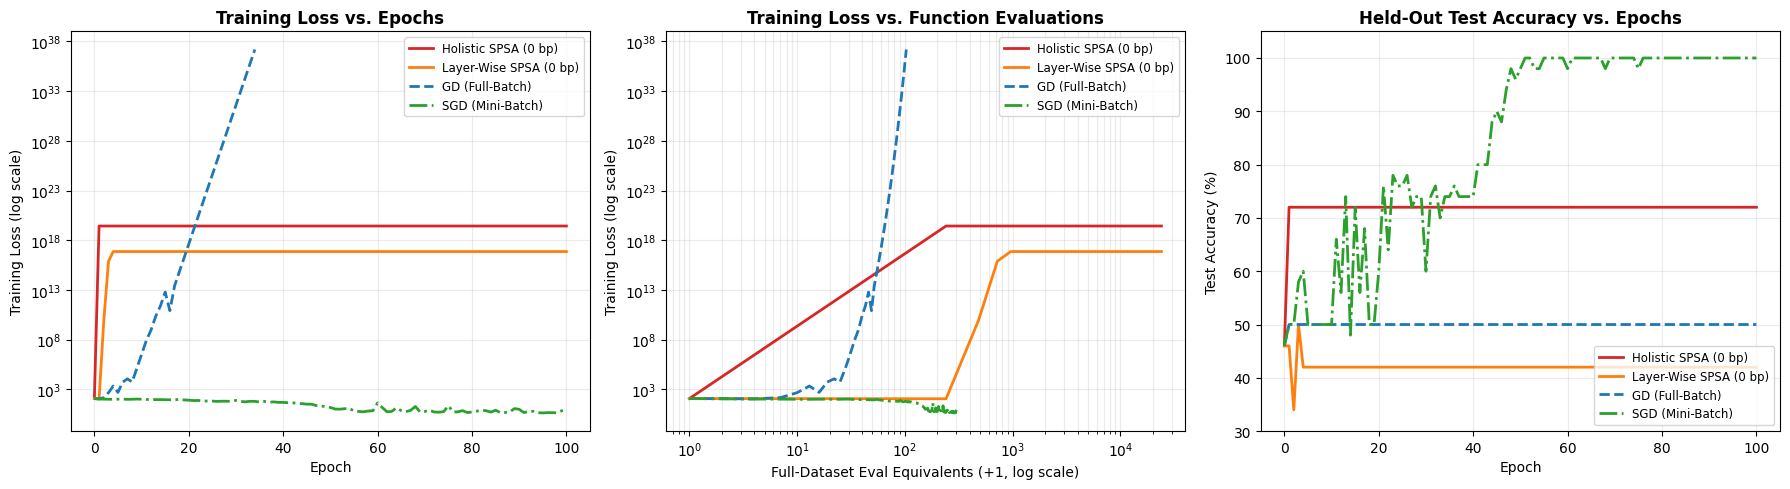

In [8]:
# Part 2 Visualizations: Loss vs. Epochs, Loss vs. Function Evaluations, Test Accuracy vs. Epochs
fig, axes = plt.subplots(1, 3, figsize=(18, 5.0))
epochs_axis = np.arange(len(hist_lw["train_loss"]))

curves = [
    ("Holistic SPSA (0 bp)",   hist_hol, "#d62728", "-"),
    ("Layer-Wise SPSA (0 bp)", hist_lw,  "#ff7f0e", "-"),
    ("GD (Full-Batch)",        hist_gd,  "#1f77b4", "--"),
    ("SGD (Mini-Batch)",       hist_sgd, "#2ca02c", "-."),
]

# Subplot 1: Training Loss vs. Epochs
ax = axes[0]
for label, h, color, style in curves:
    ax.semilogy(epochs_axis, h["train_loss"], linestyle=style, linewidth=2.0, color=color, label=label)
ax.set_title("Training Loss vs. Epochs", fontsize=12, fontweight="bold")
ax.set_xlabel("Epoch")
ax.set_ylabel("Training Loss (log scale)")
ax.legend(fontsize=8.5)
ax.grid(True, which="both", alpha=0.25)

# Subplot 2: Training Loss vs. Full-Dataset Function Evaluations (Compute-Normalized)
ax = axes[1]
for label, h, color, style in curves:
    ax.loglog(np.array(h["evals"]) + 1.0, h["train_loss"], linestyle=style, linewidth=2.0, color=color, label=label)
ax.set_title("Training Loss vs. Function Evaluations", fontsize=12, fontweight="bold")
ax.set_xlabel("Full-Dataset Eval Equivalents (+1, log scale)")
ax.set_ylabel("Training Loss (log scale)")
ax.legend(fontsize=8.5)
ax.grid(True, which="both", alpha=0.25)

# Subplot 3: Test Accuracy vs. Epochs
ax = axes[2]
for label, h, color, style in curves:
    ax.plot(epochs_axis, h["test_acc"], linestyle=style, linewidth=2.0, color=color, label=label)
ax.set_title("Held-Out Test Accuracy vs. Epochs", fontsize=12, fontweight="bold")
ax.set_xlabel("Epoch")
ax.set_ylabel("Test Accuracy (%)")
ax.set_ylim(30, 105)
ax.legend(fontsize=8.5, loc="lower right")
ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

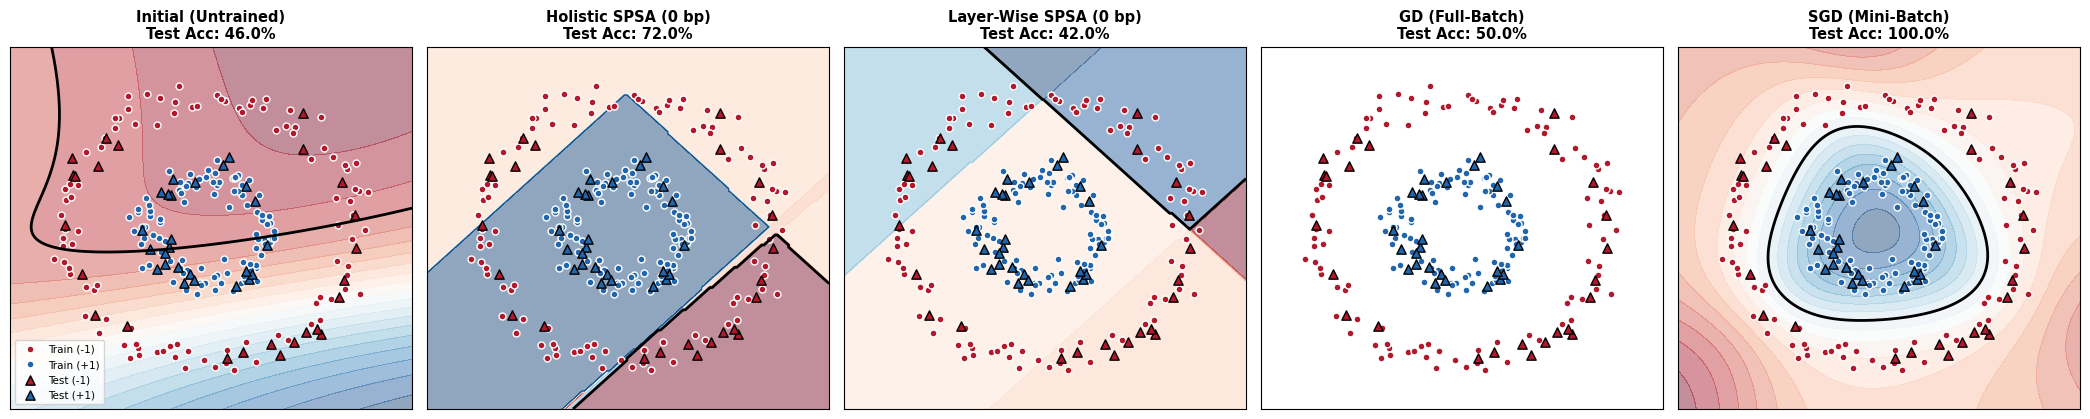

In [9]:
# Part 2 Visualization: 2D Decision Boundaries for Initial & All 4 Trained Models
fig, axes = plt.subplots(1, 5, figsize=(21, 4.3))

# Create a 2D evaluation grid
x_min, x_max = x_raw[:, 0].min() - 0.3, x_raw[:, 0].max() + 0.3
y_min, y_max = x_raw[:, 1].min() - 0.3, x_raw[:, 1].max() + 0.3
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 180), np.linspace(y_min, y_max, 180))
grid_tensor = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)

models = [
    ("Initial (Untrained)",    p0),
    ("Holistic SPSA (0 bp)",   p_hol),
    ("Layer-Wise SPSA (0 bp)", p_lw),
    ("GD (Full-Batch)",        p_gd),
    ("SGD (Mini-Batch)",       p_sgd),
]

for ax, (title, params) in zip(axes, models):
    with torch.no_grad():
        zz = forward_pass(grid_tensor, params).numpy().reshape(xx.shape)
        te_acc = compute_accuracy(forward_pass(x_test, params), y_test)

    # Shaded prediction regions and decision boundary (f(x) = 0)
    ax.contourf(xx, yy, zz, levels=20, cmap="RdBu", alpha=0.45)
    ax.contour(xx, yy, zz, levels=[0.0], colors="black", linewidths=2.0)

    # Training points (circles) and test points (triangles)
    ax.scatter(x_tr_np[y_tr_np == -1, 0], x_tr_np[y_tr_np == -1, 1], c="#b2182b", edgecolor="white", s=25, label="Train (-1)")
    ax.scatter(x_tr_np[y_tr_np ==  1, 0], x_tr_np[y_tr_np ==  1, 1], c="#2166ac", edgecolor="white", s=25, label="Train (+1)")
    ax.scatter(x_te_np[y_te_np == -1, 0], x_te_np[y_te_np == -1, 1], c="#b2182b", marker="^", edgecolor="black", s=45, label="Test (-1)")
    ax.scatter(x_te_np[y_te_np ==  1, 0], x_te_np[y_te_np ==  1, 1], c="#2166ac", marker="^", edgecolor="black", s=45, label="Test (+1)")

    ax.set_title(f"{title}\nTest Acc: {te_acc:.1f}%", fontsize=10.5, fontweight="bold")
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks([])
    ax.set_yticks([])

axes[0].legend(fontsize=7.5, loc="lower left")
plt.tight_layout()
plt.show()

## 4. Key Takeaways & Alignment with Wulff et al. (ICANN 2018)

### 4.1 Why Layer-Wise SPSA Outperforms Holistic SPSA
- **Dimensionality Variance**: Holistic SPSA perturbs all 81 parameters at once, creating high gradient-estimation variance across layers. With a summed loss and fixed step scale `a = 0.02`, large noisy updates can quickly push hidden units into `tanh` saturation and stall training.
- **Layer-Wise Decomposition**: Freezing all layers except layer $l$ reduces the perturbation dimension from $D = 81$ to a single layer's parameters at a time, allowing stable convergence to a clean circular decision boundary using **forward passes only**.

### 4.2 Comparing SPSA vs. GD / SGD (Per-Epoch vs. Per-Evaluation)
- In Section 4.2 (p. 571), Wulff et al. observe on MNIST:
  > *"While SPSA training learns within the first twelve epochs, gradient descent achieves a higher accuracy in the end."*
- Crucially, the authors also point out (pp. 570–571) that **one epoch of Layer-Wise SPSA performs many more updates than one epoch of GD**: here, Layer-Wise SPSA performs $L \times t_{\max} = 4 \times 30 = 120$ partial updates (**240 forward passes**) per epoch, compared to **3 full-dataset eval equivalents** per epoch for GD and mini-batch SGD.
- That is why **Subplot 2 (Loss vs. Function Evaluations)** is essential:
  - **Per epoch**, Layer-Wise SPSA drops loss very rapidly.
  - **Per function evaluation**, exact backpropagation (GD/SGD) is far more sample- and compute-efficient—which is expected when analytical gradients are available.
- The practical value of Layer-Wise SPSA is **not** beating backprop in wall-clock speed on standard GPUs, but enabling deep network training **without backpropagation** (useful for non-differentiable objectives, black-box simulators, or analog/neuromorphic hardware).

### 4.3 Minor Implementation Notes vs. the Paper
- **Output Activation**: Wulff et al. (Section 4.1) apply $\tanh(\beta z)$ to all layers including the output; here we use a linear output layer to avoid output saturation.
- **Layer Order & Trials**: We use bottom-up order ($L_{\text{bu}}$) on a single fixed seed (`42`); the paper averaged 100 trials and showed top-down, bottom-up, and random layer orders perform almost identically on 2D problems, only needing separate weight/bias updates when scaling to 771k parameters on MNIST.